# M4: Target Definition, Feature Engineering, and Train/Test Split
**Role:** Member 4 (M4) · **Rubric item:** Feature engineering (2 marks)

**Project:** Predicting high-pollution days in Delhi and identifying the weather and calendar conditions behind them, so businesses (construction, logistics, schools, event organisers) can plan ahead.

## Objective
Build on M2's cleaned dataset and M3's EDA findings to:
1. **Define the target** using a PM2.5-only AQI (documented rationale below).
2. **Engineer features** that capture lag, persistence, weather interactions, and calendar effects.
3. **Split into train/test** temporally (no data leakage).
4. **Save outputs** for M5 (baseline and model development).

---
### Key Design Decisions

**1. PM2.5-only AQI for the target**
- PM10 is missing on 50.8% of days, and on *every* day in 2023–2024.
- A "max(PM2.5, PM10)" AQI would mean different things in different years.
- We compute the target from `pm25_target` alone (the cleaned PM2.5 series).
- PM10 is retained as a **feature** where it exists.

**2. AQI threshold**
- CPCB PM2.5 breakpoints: AQI 301 starts at PM2.5 121 (after rounding), i.e. raw PM2.5 ≥ 120.5.
- `high_risk = 1` when `pm25_target >= 120.5` (AQI > 300).
- This target already exists in `cleaned.csv` and is verified here.

**3. PM10 as a feature only**
- PM10 is included as an input feature where observed; missing values left as NaN.

**4. Temporal train/test split**
- No shuffling. Split by date to prevent leakage.
- Training: 2018-01-01 → 2024-12-31 (7 full years)
- Test: 2025-01-01 → 2026-09-30 (~1.75 years)

## 1. Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
import warnings
warnings.filterwarnings("ignore")

# ---- Paths ----
DATA = Path("cleaned.csv")
FIG  = Path("M4_figures"); FIG.mkdir(exist_ok=True)
OUT  = Path(".")

# ---- Shared team settings (same as M3) ----
THRESH = 120.5          # AQI 301 starts at PM2.5 >= 120.5
SEVERE = 250.5          # AQI 401+ starts at PM2.5 >= 250.5
PM     = "pm25_target"  # the PM2.5 series behind high_risk

# ---- Chart style (consistent with M3) ----
BLUE, ORANGE, AQUA, RED = "#2a78d6", "#eb6834", "#1baf7a", "#d03b3b"
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 10.5, "axes.titlesize": 12.5, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlecolor": INK, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": "#c3c2b7",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False, "legend.fontsize": 9.5, "figure.dpi": 110,
})

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()

## 2. Load and verify the data

In [2]:
df = pd.read_csv(DATA, parse_dates=["date"]).sort_values("date").reset_index(drop=True)
df["year"] = df.date.dt.year
print("Shape:", df.shape, "| date range:", df.date.min().date(), "->", df.date.max().date())
print("Duplicate dates:", df.date.duplicated().sum())
miss = df.isna().sum(); miss = miss[miss > 0]
display(pd.DataFrame({"missing": miss, "missing_%": (100 * miss / len(df)).round(1)}))

Shape: (3195, 34) | date range: 2018-01-01 -> 2026-09-30
Duplicate dates: 0


,missing,missing_%
pm25_mean,262,8.2
pm25_median,262,8.2
pm25_ref_station,359,11.2
pm10_mean,1624,50.8
pm10_median,1624,50.8
prev_pm25,262,8.2
next_pm25,263,8.2
high_risk,272,8.5
high_risk_city,262,8.2
pm25_target,272,8.5


## 3. Verify the target definition

The target `high_risk` was built in M2 from `pm25_target >= 120.5`. We verify this is correct and show its distribution. **PM10 is not used in the target** because it is missing on 50.8% of days (and 100% in 2023–2024). PM10 is kept only as a feature.

In [3]:
# Verify high_risk matches pm25_target >= THRESH
t_ok = df.dropna(subset=[PM])
assert ((t_ok[PM] >= THRESH).astype(float) == t_ok.high_risk).all(), \
    "high_risk does not match pm25_target >= THRESH"
print("Verified: high_risk == (pm25_target >= 120.5) on all", len(t_ok), "rows with a target.")

# ---- CPCB AQI sub-index (for visualisation) ----
CPCB_BREAKS = [(0, 30, 0, 50), (31, 60, 51, 100), (61, 90, 101, 200),
               (91, 120, 201, 300), (121, 250, 301, 400), (251, 380, 401, 500)]

def pm25_to_aqi(pm25):
    pm25 = np.asarray(pm25, dtype=float)
    aqi  = np.full_like(pm25, np.nan, dtype=float)
    for cp_lo, cp_hi, ip_lo, ip_hi in CPCB_BREAKS:
        m = (pm25 >= cp_lo) & (pm25 <= cp_hi)
        aqi = np.where(m & np.isnan(aqi),
                       ip_lo + (pm25 - cp_lo) * (ip_hi - ip_lo) / (cp_hi - cp_lo), aqi)
    aqi = np.where((pm25 > 380) & np.isnan(aqi), 500.0, aqi)
    return aqi

df["aqi_pm25"] = pm25_to_aqi(df[PM].values)

# ---- Category ----
bins   = [-np.inf, 30.5, 60.5, 90.5, 120.5, 250.5, np.inf]
labels = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]
df["aqi_category"] = pd.cut(df[PM], bins=bins, labels=labels, right=False)

# ---- Print distribution ----
valid = df.dropna(subset=["high_risk"])
cat   = valid["aqi_category"].value_counts().reindex(labels)
display(pd.DataFrame({"days": cat, "share_%": (100 * cat / cat.sum()).round(1)}))
n_high, n_valid = int(valid.high_risk.sum()), len(valid)
print(f"\nhigh_risk = 1 : {n_high} of {n_valid} days ({100*n_high/n_valid:.1f}%)")
print(f"high_risk = 0 : {n_valid-n_high} of {n_valid} days ({100*(n_valid-n_high)/n_valid:.1f}%)")
print(f"Excluded (no target) : {len(df)-n_valid} days")

Verified: high_risk == (pm25_target >= 120.5) on all 2923 rows with a target.


,days,share_%
aqi_category,,
Good,500,17.1
Satisfactory,816,27.9
Moderate,519,17.8
Poor,296,10.1
Very Poor,619,21.2
Severe,173,5.9



high_risk = 1 : 792 of 2923 days (27.1%)
high_risk = 0 : 2131 of 2923 days (72.9%)
Excluded (no target) : 272 days


### Target distribution

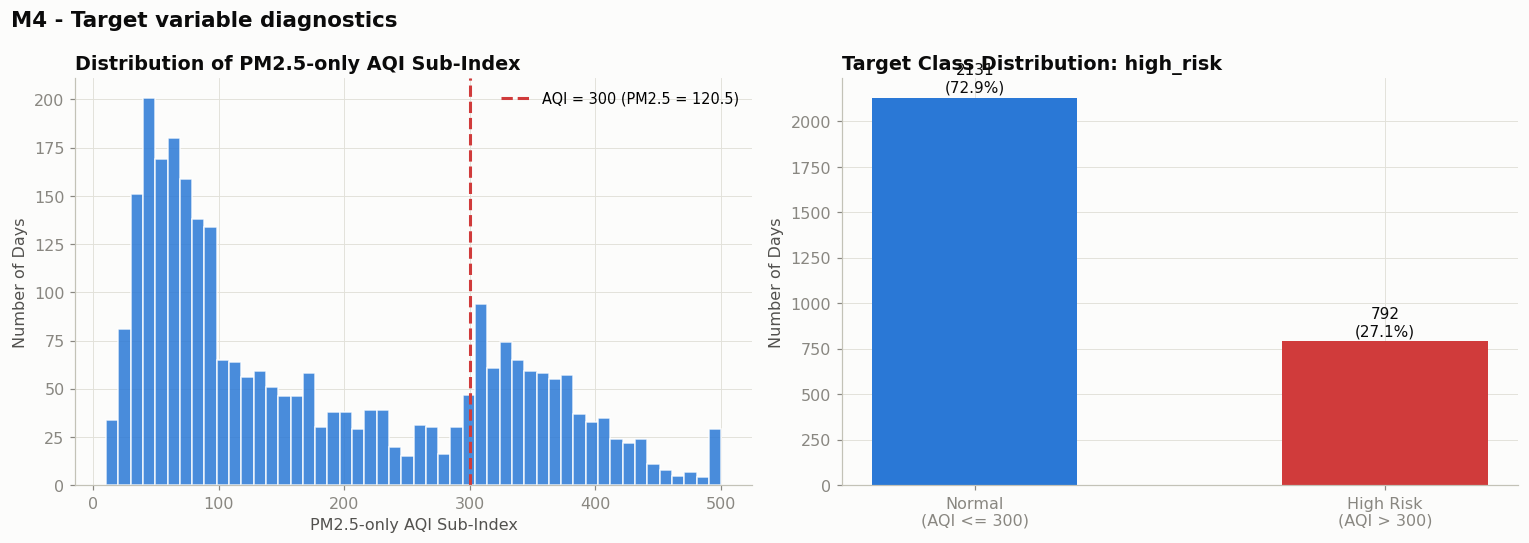

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
aqi_v = valid["aqi_pm25"].dropna()
ax.hist(aqi_v, bins=50, color=BLUE, edgecolor="white", alpha=0.85)
ax.axvline(300, color=RED, lw=2, ls="--", label="AQI = 300 (PM2.5 = 120.5)")
ax.set_xlabel("PM2.5-only AQI Sub-Index"); ax.set_ylabel("Number of Days")
ax.set_title("Distribution of PM2.5-only AQI Sub-Index"); ax.legend(loc="upper right")

ax = axes[1]
cc = valid.high_risk.value_counts().sort_index()
bars = ax.bar(["Normal\n(AQI <= 300)", "High Risk\n(AQI > 300)"], cc.values, color=[BLUE, RED], width=0.5)
for b, v in zip(bars, cc.values):
    ax.text(b.get_x() + b.get_width()/2, v+15, f"{int(v)}\n({100*v/n_valid:.1f}%)",
            ha="center", va="bottom", fontsize=10, color=INK)
ax.set_ylabel("Number of Days"); ax.set_title("Target Class Distribution: high_risk")

fig.suptitle("M4 - Target variable diagnostics", x=0.01, ha="left", fontsize=14, fontweight="bold", color=INK)
fig.tight_layout(); save(fig, "01_target_distribution")

## 4. Feature Engineering

Features are grouped into seven families. **All lag and rolling features use `shift(1)` or more** so that no same-day target information leaks into predictors.

### 4a. Lag features (t-1, t-2, t-3)

In [5]:
lag_cols = ["pm25_mean", "pm10_mean", "temp_mean", "humidity_mean",
            "wind_speed_mean", "pressure_mean", "precip_sum", "cloud_mean", "aqi_pm25"]
for col in lag_cols:
    for lag in [1, 2, 3]:
        df[f"{col}_lag{lag}"] = df[col].shift(lag)
print(f"Created {len(lag_cols)*3} lag features for: {lag_cols}")

Created 27 lag features for: ['pm25_mean', 'pm10_mean', 'temp_mean', 'humidity_mean', 'wind_speed_mean', 'pressure_mean', 'precip_sum', 'cloud_mean', 'aqi_pm25']


### 4b. Rolling-window features (3-day and 7-day)

In [6]:
roll_cols = ["pm25_mean", "temp_mean", "humidity_mean",
             "wind_speed_mean", "pressure_mean", "precip_sum"]
for col in roll_cols:
    for w in [3, 7]:
        shifted = df[col].shift(1)
        df[f"{col}_roll{w}_mean"] = shifted.rolling(w, min_periods=1).mean()
        df[f"{col}_roll{w}_std"]  = shifted.rolling(w, min_periods=1).std()
print(f"Created {len(roll_cols)*4} rolling features (shift(1) to avoid leakage)")

Created 24 rolling features (shift(1) to avoid leakage)


### 4c. Day-over-day change features

In [7]:
change_cols = ["pm25_mean", "temp_mean", "humidity_mean", "wind_speed_mean", "pressure_mean"]
for col in change_cols:
    df[f"{col}_change"] = df[col] - df[col].shift(1)
print(f"Created {len(change_cols)} change features")

Created 5 change features


### 4d. Weather interaction features

In [8]:
df["temp_range"]                  = df["temp_max"] - df["temp_min"]
df["wind_humidity_interaction"]   = df["wind_speed_mean"] * df["humidity_mean"]
df["temp_pressure_interaction"]   = df["temp_mean"] * df["pressure_mean"]
df["low_wind"]     = (df["wind_speed_mean"] < 1.5).astype(int)
df["is_dry_day"]   = (df["precip_sum"] == 0).astype(int)
df["high_humidity"] = (df["humidity_mean"] > 75).astype(int)
df["is_cold_day"]  = (df["temp_mean"] < 15).astype(int)
df["cold_calm_dry"] = (df["is_cold_day"] & df["low_wind"] & df["is_dry_day"]).astype(int)
print("Created 8 weather interaction / indicator features")

Created 8 weather interaction / indicator features


### 4e. Enhanced calendar features

In [9]:
doy = df.date.dt.dayofyear
df["day_of_year_sin"] = np.sin(2 * np.pi * doy / 365.25)
df["day_of_year_cos"] = np.cos(2 * np.pi * doy / 365.25)
df["month_sin"]       = np.sin(2 * np.pi * df["month"] / 12)
df["month_cos"]       = np.cos(2 * np.pi * df["month"] / 12)
df["is_winter"]       = df["month"].isin([11, 12, 1, 2]).astype(int)
df["is_post_monsoon"] = df["month"].isin([10, 11]).astype(int)
df["diwali_within_3d"]  = (df["days_from_diwali"].abs() <= 3).astype(int)
df["diwali_within_7d"]  = (df["days_from_diwali"].abs() <= 7).astype(int)
df["diwali_within_14d"] = (df["days_from_diwali"].abs() <= 14).astype(int)
print("Created 9 calendar / cyclical features")

Created 9 calendar / cyclical features


### 4f. Pollution persistence features

In [10]:
df["prev_high_risk"]    = df["high_risk"].shift(1)
df["high_risk_past3d"]  = df["high_risk"].shift(1).rolling(3, min_periods=1).sum()
df["high_risk_past7d"]  = df["high_risk"].shift(1).rolling(7, min_periods=1).sum()
print("Created 3 persistence features (from M3 EDA: strong day-to-day autocorrelation)")

Created 3 persistence features (from M3 EDA: strong day-to-day autocorrelation)


### 4g. PM10 as a feature (where available)

In [11]:
df["pm10_available"]  = df["pm10_mean"].notna().astype(int)
df["pm25_pm10_ratio"] = np.where(
    df["pm10_mean"].notna() & (df["pm10_mean"] > 0),
    df["pm25_mean"] / df["pm10_mean"], np.nan)
print("Created 2 PM10 feature columns (PM10 is NOT in the target)")
print(f"PM10 available on {df.pm10_available.sum()} of {len(df)} days ({100*df.pm10_available.mean():.1f}%)")

Created 2 PM10 feature columns (PM10 is NOT in the target)
PM10 available on 1571 of 3195 days (49.2%)


### 4h. Season one-hot encoding

In [12]:
season_dummies = pd.get_dummies(df["season"], prefix="season", dtype=int)
df = pd.concat([df, season_dummies], axis=1)
print("Created", len(season_dummies.columns), "season dummy columns:", list(season_dummies.columns))

Created 4 season dummy columns: ['season_monsoon', 'season_post_monsoon', 'season_pre_monsoon', 'season_winter']


### Feature summary

In [13]:
original_cols = [
    "date", "pm25_mean", "pm25_median", "pm25_n_stations", "pm25_n_extreme_flagged",
    "pm25_ref_station", "pm10_mean", "pm10_median", "pm10_n_stations", "pm10_n_extreme_flagged",
    "temp_mean", "temp_min", "temp_max", "humidity_mean", "dewpoint_mean",
    "wind_speed_mean", "wind_gust_max", "pressure_mean", "precip_sum", "cloud_mean", "wind_dir_deg",
    "month", "day_of_week", "is_weekend", "season", "days_from_diwali", "is_festival_window",
    "year", "prev_pm25", "next_pm25", "high_risk", "high_risk_city", "pm25_target", "target_source",
]
derived = [c for c in df.columns if c not in original_cols]
print(f"Total columns: {len(df.columns)} | Original: {len(original_cols)} | Derived: {len(derived)}")
print("\nAll derived features:")
for i, c in enumerate(derived, 1):
    print(f"  {i:3d}. {c}")

Total columns: 118 | Original: 34 | Derived: 84

All derived features:
    1. aqi_pm25
    2. aqi_category
    3. pm25_mean_lag1
    4. pm25_mean_lag2
    5. pm25_mean_lag3
    6. pm10_mean_lag1
    7. pm10_mean_lag2
    8. pm10_mean_lag3
    9. temp_mean_lag1
   10. temp_mean_lag2
   11. temp_mean_lag3
   12. humidity_mean_lag1
   13. humidity_mean_lag2
   14. humidity_mean_lag3
   15. wind_speed_mean_lag1
   16. wind_speed_mean_lag2
   17. wind_speed_mean_lag3
   18. pressure_mean_lag1
   19. pressure_mean_lag2
   20. pressure_mean_lag3
   21. precip_sum_lag1
   22. precip_sum_lag2
   23. precip_sum_lag3
   24. cloud_mean_lag1
   25. cloud_mean_lag2
   26. cloud_mean_lag3
   27. aqi_pm25_lag1
   28. aqi_pm25_lag2
   29. aqi_pm25_lag3
   30. pm25_mean_roll3_mean
   31. pm25_mean_roll3_std
   32. pm25_mean_roll7_mean
   33. pm25_mean_roll7_std
   34. temp_mean_roll3_mean
   35. temp_mean_roll3_std
   36. temp_mean_roll7_mean
   37. temp_mean_roll7_std
   38. humidity_mean_roll3_mean
  

## 5. Filter rows with valid target

Drop rows where `high_risk` is NaN (no PM2.5 target). Also skip the first 3 rows because lag features are undefined there.

In [14]:
df_model = df.dropna(subset=["high_risk"]).copy()
df_model = df_model.iloc[3:].reset_index(drop=True)
print(f"Rows available for modelling: {len(df_model)}")
print(f"Rows dropped (no target or lag warm-up): {len(df) - len(df_model)}")

Rows available for modelling: 2920
Rows dropped (no target or lag warm-up): 275


## 6. Train / Test Split (temporal)

We split by date, **not randomly**, to prevent data leakage. The model must predict *genuinely future* days.
- **Train:** 2018-01-01 → 2024-12-31 (7 full years)
- **Test:** 2025-01-01 → 2026-09-30 (~1.75 years)

In [15]:
SPLIT_DATE = pd.Timestamp("2025-01-01")

df_train = df_model[df_model.date < SPLIT_DATE].copy()
df_test  = df_model[df_model.date >= SPLIT_DATE].copy()
n_total  = len(df_train) + len(df_test)

print(f"Split date : {SPLIT_DATE.date()}")
print(f"Training   : {df_train.date.min().date()} -> {df_train.date.max().date()}  ({len(df_train)} rows)")
print(f"Testing    : {df_test.date.min().date()} -> {df_test.date.max().date()}  ({len(df_test)} rows)")
print(f"Ratio      : {100*len(df_train)/n_total:.1f}% train / {100*len(df_test)/n_total:.1f}% test")
print()
for name, sub in [("Train", df_train), ("Test", df_test)]:
    n, h = len(sub), int(sub.high_risk.sum())
    print(f"  {name}: high_risk=1 -> {h} ({100*h/n:.1f}%),  high_risk=0 -> {n-h} ({100*(n-h)/n:.1f}%)")

Split date : 2025-01-01
Training   : 2018-01-04 -> 2024-12-31  (2285 rows)
Testing    : 2025-01-01 -> 2026-09-29  (635 rows)
Ratio      : 78.3% train / 21.7% test

  Train: high_risk=1 -> 661 (28.9%),  high_risk=0 -> 1624 (71.1%)
  Test: high_risk=1 -> 128 (20.2%),  high_risk=0 -> 507 (79.8%)


## 7. Feature list for M5

These columns will be used as model inputs. **Excluded:** date, year, all target-related columns (`pm25_mean`, `pm25_target`, `high_risk`, `aqi_pm25`, etc.), leaky columns (`next_pm25`), and the raw `season` string (replaced by dummies).

In [16]:
EXCLUDE = [
    "date", "year",
    "pm25_mean", "pm25_median", "pm25_ref_station",
    "pm25_n_stations", "pm25_n_extreme_flagged",
    "pm25_target", "aqi_pm25", "high_risk", "aqi_category",
    "high_risk_city", "target_source",
    "prev_pm25", "next_pm25",
    "pm10_median", "pm10_n_stations", "pm10_n_extreme_flagged",
    "season",
]
FEATURES = [c for c in df_model.columns if c not in EXCLUDE]
TARGET   = "high_risk"

print(f"Feature columns for M5: {len(FEATURES)} features")
for i, c in enumerate(FEATURES, 1):
    print(f"  {i:3d}. {c}")

Feature columns for M5: 99 features
    1. pm10_mean
    2. temp_mean
    3. temp_min
    4. temp_max
    5. humidity_mean
    6. dewpoint_mean
    7. wind_speed_mean
    8. wind_gust_max
    9. pressure_mean
   10. precip_sum
   11. cloud_mean
   12. wind_dir_deg
   13. month
   14. day_of_week
   15. is_weekend
   16. days_from_diwali
   17. is_festival_window
   18. pm25_mean_lag1
   19. pm25_mean_lag2
   20. pm25_mean_lag3
   21. pm10_mean_lag1
   22. pm10_mean_lag2
   23. pm10_mean_lag3
   24. temp_mean_lag1
   25. temp_mean_lag2
   26. temp_mean_lag3
   27. humidity_mean_lag1
   28. humidity_mean_lag2
   29. humidity_mean_lag3
   30. wind_speed_mean_lag1
   31. wind_speed_mean_lag2
   32. wind_speed_mean_lag3
   33. pressure_mean_lag1
   34. pressure_mean_lag2
   35. pressure_mean_lag3
   36. precip_sum_lag1
   37. precip_sum_lag2
   38. precip_sum_lag3
   39. cloud_mean_lag1
   40. cloud_mean_lag2
   41. cloud_mean_lag3
   42. aqi_pm25_lag1
   43. aqi_pm25_lag2
   44. aqi_pm25_l

## 8. Diagnostic visualisations

### 8a. Feature correlations with target

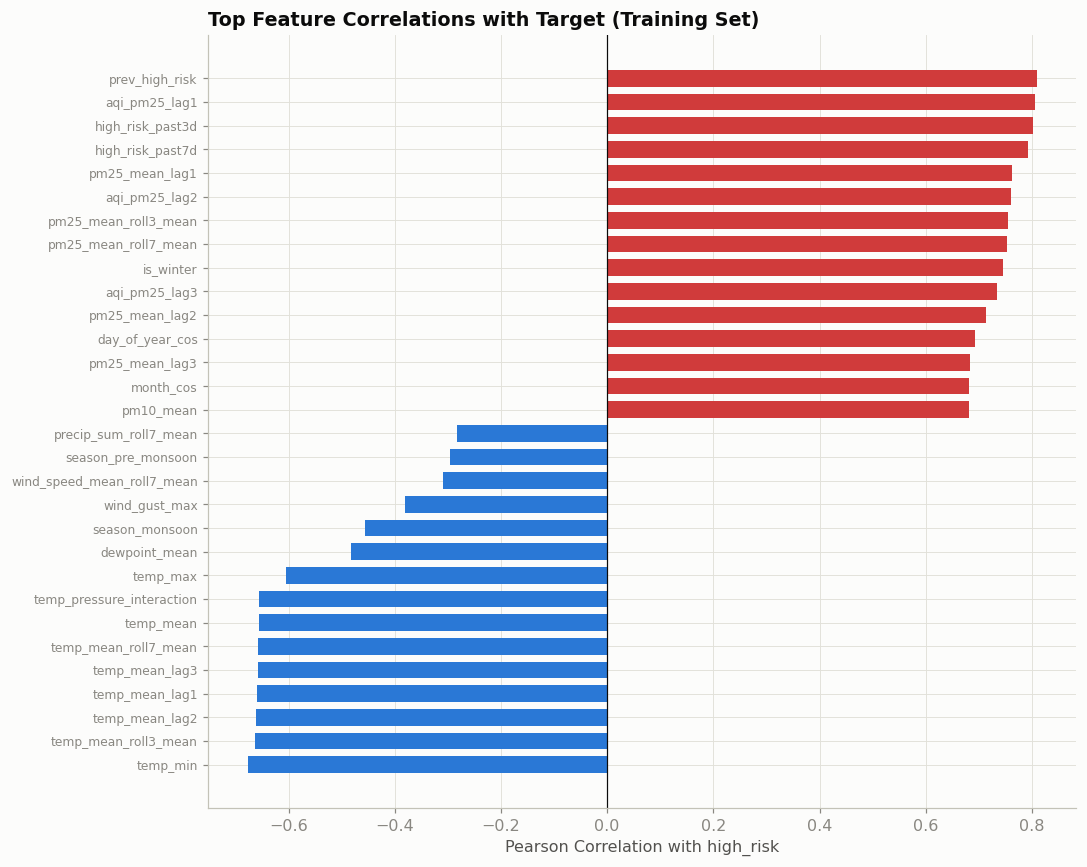

In [17]:
corr = df_train[FEATURES + [TARGET]].corr()[TARGET].drop(TARGET).dropna().sort_values(ascending=False)
top_n = min(30, len(corr))
top = pd.concat([corr.head(top_n // 2), corr.tail(top_n // 2)])

fig, ax = plt.subplots(figsize=(10, max(8, len(top) * 0.25)))
colors = [RED if v > 0 else BLUE for v in top.values]
ax.barh(range(len(top)), top.values, color=colors, height=0.7)
ax.set_yticks(range(len(top))); ax.set_yticklabels(top.index, fontsize=8)
ax.set_xlabel("Pearson Correlation with high_risk")
ax.set_title("Top Feature Correlations with Target (Training Set)")
ax.axvline(0, color=INK, lw=0.8); ax.invert_yaxis()
fig.tight_layout(); save(fig, "02_feature_correlations")

### 8b. AQI time series with train/test split

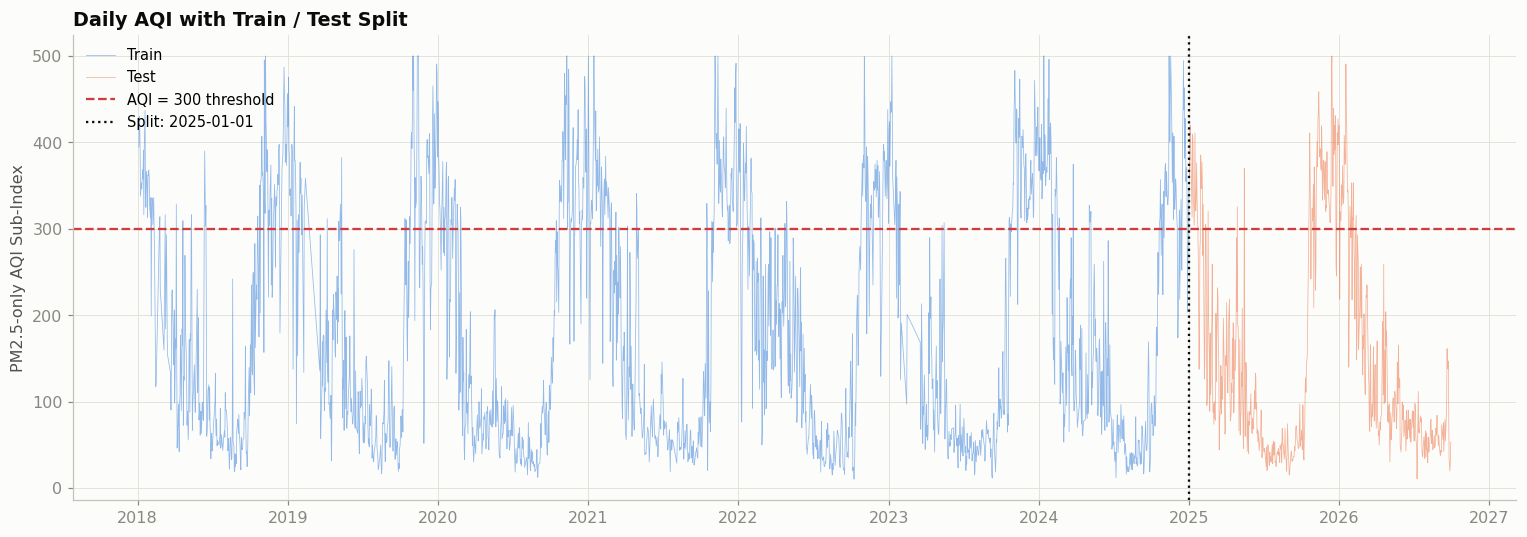

In [18]:
fig, ax = plt.subplots(figsize=(14, 5))
tr = df_train.set_index("date")["aqi_pm25"].dropna()
te = df_test.set_index("date")["aqi_pm25"].dropna()
ax.plot(tr.index, tr.values, color=BLUE, alpha=0.5, lw=0.5, label="Train")
ax.plot(te.index, te.values, color=ORANGE, alpha=0.5, lw=0.5, label="Test")
ax.axhline(300, color=RED, lw=1.5, ls="--", label="AQI = 300 threshold")
ax.axvline(SPLIT_DATE, color=INK, lw=1.5, ls=":", label=f"Split: {SPLIT_DATE.date()}")
ax.set_ylabel("PM2.5-only AQI Sub-Index"); ax.set_title("Daily AQI with Train / Test Split")
ax.legend(loc="upper left")
ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout(); save(fig, "03_train_test_split")

### 8c. High-risk day frequency by year

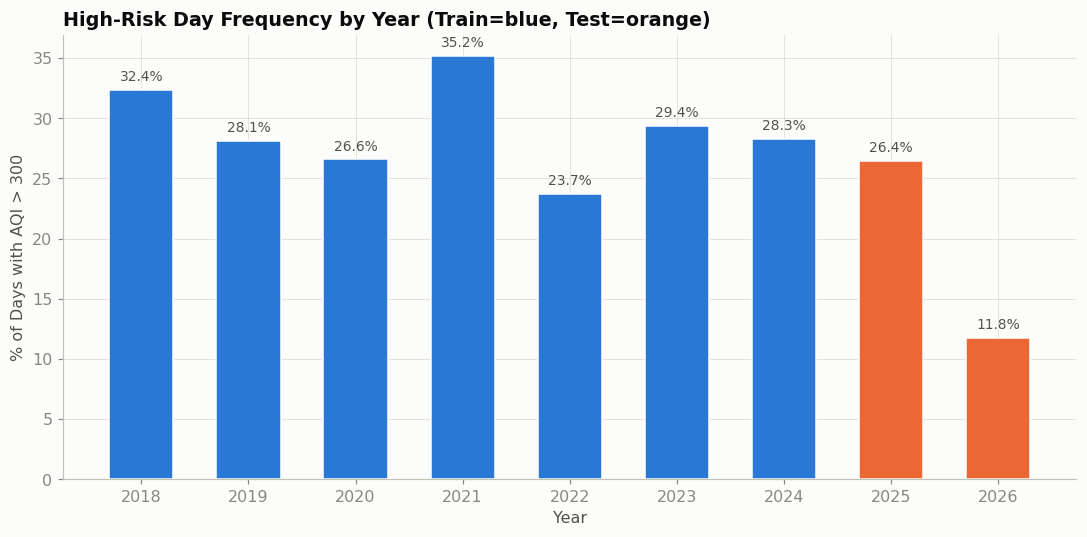

In [19]:
fig, ax = plt.subplots(figsize=(10, 5))
yr = df_model.groupby("year").agg(total=("high_risk", "count"), high=("high_risk", "sum")).reset_index()
yr["pct"] = 100 * yr["high"] / yr["total"]
bars = ax.bar(yr["year"], yr["pct"],
              color=[BLUE if y < 2025 else ORANGE for y in yr["year"]], width=0.6, edgecolor="white")
for b, v in zip(bars, yr["pct"]):
    ax.text(b.get_x() + b.get_width()/2, v+0.5, f"{v:.1f}%", ha="center", va="bottom", fontsize=9, color=INK2)
ax.set_xlabel("Year"); ax.set_ylabel("% of Days with AQI > 300")
ax.set_title("High-Risk Day Frequency by Year (Train=blue, Test=orange)")
ax.set_xticks(yr["year"]); fig.tight_layout(); save(fig, "04_high_risk_by_year")

## 9. Save outputs for M5

In [20]:
# Full engineered dataset
df.to_csv(OUT / "m4_full_engineered.csv", index=False)
print(f"Full engineered dataset -> m4_full_engineered.csv ({len(df)} rows, {len(df.columns)} cols)")

# Train / test
df_train.to_csv(OUT / "m4_train.csv", index=False)
df_test.to_csv(OUT / "m4_test.csv", index=False)
print(f"Training set -> m4_train.csv ({len(df_train)} rows)")
print(f"Test set     -> m4_test.csv  ({len(df_test)} rows)")

# Feature metadata
feat_info = pd.DataFrame({
    "feature": FEATURES,
    "dtype": [str(df_model[c].dtype) for c in FEATURES],
    "missing_train_%": [round(100*df_train[c].isna().sum()/len(df_train), 1) for c in FEATURES],
    "missing_test_%":  [round(100*df_test[c].isna().sum()/len(df_test), 1) for c in FEATURES],
})
feat_info.to_csv(OUT / "m4_feature_list.csv", index=False)
display(feat_info)
print(f"Feature list -> m4_feature_list.csv ({len(FEATURES)} features)")

Full engineered dataset -> m4_full_engineered.csv (3195 rows, 118 cols)


Training set -> m4_train.csv (2285 rows)
Test set     -> m4_test.csv  (635 rows)


,feature,dtype,missing_train_%,missing_test_%
0,pm10_mean,float64,56.0,12.8
1,temp_mean,float64,0.0,0.0
2,temp_min,float64,0.0,0.0
3,temp_max,float64,0.0,0.0
4,humidity_mean,float64,0.0,0.0
...,...,...,...,...
94,pm25_pm10_ratio,float64,56.0,12.8
95,season_monsoon,int64,0.0,0.0
96,season_post_monsoon,int64,0.0,0.0
97,season_pre_monsoon,int64,0.0,0.0


Feature list -> m4_feature_list.csv (99 features)


## 10. Summary

| Item | Detail |
|---|---|
| **Target** | `high_risk` = 1 when `pm25_target >= 120.5` (AQI > 300, "Very Poor" or "Severe") |
| **AQI basis** | PM2.5-only (PM10 excluded from target: 50.8% missing, 0% in 2023–2024) |
| **PM10** | Kept as a feature only, with availability flag |
| **Features** | Lag (t-1/2/3), rolling (3d/7d), changes, weather interactions, calendar/cyclical, Diwali proximity, persistence, season dummies |
| **Split** | Temporal at 2025-01-01 (no shuffling) |
| **Outputs** | `m4_full_engineered.csv`, `m4_train.csv`, `m4_test.csv`, `m4_feature_list.csv`, figures in `M4_figures/` |

All features use only past information (shift >= 1). No future data leaks into the training set. M5 can now build baseline and advanced models on these outputs.